# W6S3 – Text Clustering for Movies

**Nama:** Don Bosco Simorangkir
**NIM:** 42324035
**Praktikum:** Week 6 Session 3  
**Topik:** Text Clustering

## Tujuan Praktikum

Melakukan tahapan clustering teks, mulai dari preprocessing, ekstraksi fitur menggunakan TF-IDF, pengelompokan teks dengan algoritma K-Means, hingga visualisasi hasil clustering menggunakan PCA.

## 1. Import Library

Pada tahap ini, kita mengimpor library yang diperlukan untuk pengolahan data, preprocessing teks, clustering, dan visualisasi.

- `pandas` dan `numpy`: mengolah data.
- `re` dan `string`: membersihkan teks.
- `nltk`: melakukan tokenisasi dan lemmatisasi.
- `TfidfVectorizer`: mengubah teks menjadi fitur numerik.
- `KMeans`: mengelompokkan teks.
- `PCA`: mereduksi fitur menjadi dua komponen agar hasil clustering dapat divisualisasikan.

In [1]:
# Import library
import pandas as pd
import numpy as np
import re
import string
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

## 2. Persiapan Resource NLTK

NLTK membutuhkan data bahasa untuk menjalankan tokenisasi dan lemmatisasi. Cell berikut mengunduh resource yang diperlukan jika belum tersedia.

Langkah ini merupakan persiapan tambahan agar kode pada modul dapat dijalankan.

In [2]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\donbo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\donbo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\donbo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

## 3. Load Dataset

Dataset yang digunakan adalah TMDB 5000 Movies (`tmdb_5000_movies.csv.gz`). Dataset ini berisi informasi film, termasuk judul dan deskripsi film pada kolom `overview`.

Pada praktikum ini, kolom `overview` digunakan sebagai teks yang akan dikelompokkan. Nama kolom tersebut kemudian diubah menjadi `text` agar sesuai dengan tahapan preprocessing berikutnya.

In [3]:
# Load dataset
file_path = "tmdb_5000_movies.csv.gz"
df = pd.read_csv(file_path, compression="gzip")

# Mengambil kolom yang diperlukan
df = df[['title', 'overview']].copy()

# Mengubah nama kolom overview menjadi text
df = df.rename(columns={'overview': 'text'})

# Menghapus data yang tidak memiliki deskripsi film
df = df.dropna(subset=['text'])

# Menampilkan beberapa data
df.head()

,title,text
0,Avatar,"In the 22nd century, a paraplegic Marine is di..."
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha..."
2,Spectre,A cryptic message from Bond’s past sends him o...
3,The Dark Knight Rises,Following the death of District Attorney Harve...
4,John Carter,"John Carter is a war-weary, former military ca..."


## 4. Text Preprocessing

Preprocessing dilakukan untuk membersihkan teks sebelum proses clustering.

Tahapan yang digunakan:

1. **Lowercasing:** mengubah semua huruf menjadi huruf kecil.
2. **Menghapus angka:** menghilangkan digit dari teks.
3. **Menghapus tanda baca:** menghilangkan karakter tanda baca.
4. **Tokenisasi:** memecah teks menjadi kata-kata.
5. **Lemmatization:** mengubah kata ke bentuk dasarnya berdasarkan aturan bahasa.

Hasil pembersihan disimpan dalam kolom `clean_text`.

In [4]:
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower()  # Lowercasing
    text = re.sub(r'\d+', '', text)  # Hapus angka
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )  # Hapus tanda baca
    words = word_tokenize(text)  # Tokenisasi
    words = [
        lemmatizer.lemmatize(word) for word in words
    ]  # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['text'].apply(clean_text)

# Menampilkan hasil preprocessing
df[['title', 'text', 'clean_text']].head()

,title,text,clean_text
0,Avatar,"In the 22nd century, a paraplegic Marine is di...",in the nd century a paraplegic marine is dispa...
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",captain barbossa long believed to be dead ha c...
2,Spectre,A cryptic message from Bond’s past sends him o...,a cryptic message from bond ’ s past sends him...
3,The Dark Knight Rises,Following the death of District Attorney Harve...,following the death of district attorney harve...
4,John Carter,"John Carter is a war-weary, former military ca...",john carter is a warweary former military capt...


## 5. Feature Extraction dengan TF-IDF

TF-IDF (*Term Frequency–Inverse Document Frequency*) digunakan untuk mengubah deskripsi film menjadi representasi numerik. Metode ini memberikan bobot berdasarkan frekuensi kata dalam dokumen dan tingkat keumuman kata pada seluruh dokumen.

Parameter `stop_words='english'` digunakan untuk mengabaikan kata-kata umum dalam bahasa Inggris. Hasil konversi disimpan dalam variabel `X` untuk digunakan oleh K-Means.

In [5]:
# Konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df['clean_text'])

print("Ukuran matriks TF-IDF:", X.shape)

Ukuran matriks TF-IDF: (4800, 20249)


## 6. Text Clustering dengan K-Means

K-Means digunakan untuk mengelompokkan film berdasarkan kemiripan fitur TF-IDF dari deskripsinya.

Parameter `n_clusters=2` menentukan jumlah kelompok sebanyak dua cluster. `random_state=42` membantu menghasilkan pengelompokan yang konsisten, sedangkan `n_init=10` menentukan jumlah percobaan inisialisasi centroid.

Label cluster setiap film disimpan dalam kolom `cluster`.

In [6]:
# Tentukan jumlah klaster
num_clusters = 2

kmeans = KMeans(
    n_clusters=num_clusters,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X)

# Menampilkan hasil clustering
df[['title', 'text', 'cluster']].head(10)

,title,text,cluster
0,Avatar,"In the 22nd century, a paraplegic Marine is di...",0
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",1
2,Spectre,A cryptic message from Bond’s past sends him o...,0
3,The Dark Knight Rises,Following the death of District Attorney Harve...,0
4,John Carter,"John Carter is a war-weary, former military ca...",0
5,Spider-Man 3,The seemingly invincible Spider-Man goes up ag...,0
6,Tangled,When the kingdom's most wanted-and most charmi...,0
7,Avengers: Age of Ultron,When Tony Stark tries to jumpstart a dormant p...,0
8,Harry Potter and the Half-Blood Prince,"As Harry begins his sixth year at Hogwarts, he...",1
9,Batman v Superman: Dawn of Justice,Fearing the actions of a god-like Super Hero l...,0


### Distribusi Film pada Setiap Cluster

Tahap ini digunakan untuk mengetahui jumlah film yang masuk ke setiap cluster. Informasi tersebut membantu melihat distribusi hasil pengelompokan.

In [7]:
# Menghitung jumlah film pada setiap cluster
df['cluster'].value_counts().sort_index()

cluster
0    3251
1    1549
Name: count, dtype: int64

## 7. Visualisasi Hasil Clustering dengan PCA

PCA (*Principal Component Analysis*) digunakan untuk mereduksi fitur TF-IDF menjadi dua komponen agar hasil clustering dapat divisualisasikan dalam grafik dua dimensi.

Setiap titik mewakili satu film, sedangkan warna menunjukkan cluster yang diberikan oleh K-Means. PCA hanya digunakan untuk visualisasi, bukan untuk menentukan cluster.

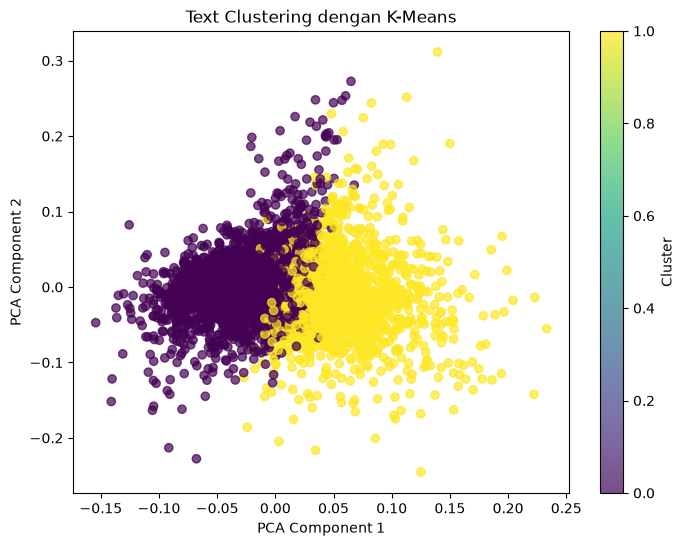

In [8]:
# Visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['cluster'],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()

## 8. Analisis Hasil Clustering

Pada tahap ini, kita meninjau contoh film dalam setiap cluster untuk memahami karakteristik kelompok yang terbentuk.

Label `0` dan `1` merupakan penanda kelompok, bukan peringkat kualitas film. Karakteristik cluster perlu ditafsirkan berdasarkan kesamaan isi deskripsi film yang berada di dalamnya.

In [9]:
# Menampilkan 10 film pertama dari setiap cluster
for cluster_id in sorted(df['cluster'].unique()):
    print(f"\nCluster {cluster_id}")
    display(
        df.loc[
            df['cluster'] == cluster_id,
            ['title', 'text']
        ].head(10)
    )


Cluster 0


,title,text
0,Avatar,"In the 22nd century, a paraplegic Marine is di..."
2,Spectre,A cryptic message from Bond’s past sends him o...
3,The Dark Knight Rises,Following the death of District Attorney Harve...
4,John Carter,"John Carter is a war-weary, former military ca..."
5,Spider-Man 3,The seemingly invincible Spider-Man goes up ag...
6,Tangled,When the kingdom's most wanted-and most charmi...
7,Avengers: Age of Ultron,When Tony Stark tries to jumpstart a dormant p...
9,Batman v Superman: Dawn of Justice,Fearing the actions of a god-like Super Hero l...
10,Superman Returns,Superman returns to discover his 5-year absenc...
11,Quantum of Solace,Quantum of Solace continues the adventures of ...



Cluster 1


,title,text
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha..."
8,Harry Potter and the Half-Blood Prince,"As Harry begins his sixth year at Hogwarts, he..."
14,Man of Steel,A young boy learns that he has extraordinary p...
15,The Chronicles of Narnia: Prince Caspian,One year after their incredible adventures in ...
17,Pirates of the Caribbean: On Stranger Tides,Captain Jack Sparrow crosses paths with a woma...
20,The Amazing Spider-Man,Peter Parker is an outcast high schooler aband...
21,Robin Hood,When soldier Robin happens upon the dying Robe...
25,Titanic,"84 years later, a 101-year-old woman named Ros..."
38,The Amazing Spider-Man 2,"For Peter Parker, life is busy. Between taking..."
47,Star Trek Into Darkness,When the crew of the Enterprise is called back...


In [10]:
# Simpan hasil clustering
df.to_csv("tmdb_clustering_results.csv", index=False)

print("Hasil clustering berhasil disimpan.")

Hasil clustering berhasil disimpan.


## 9. Kesimpulan

Pada praktikum ini, clustering teks dilakukan terhadap deskripsi film dari dataset TMDB 5000 Movies. Proses dimulai dengan preprocessing teks, dilanjutkan dengan ekstraksi fitur menggunakan TF-IDF, pengelompokan menggunakan K-Means menjadi dua cluster, dan visualisasi menggunakan PCA.

Hasil clustering menunjukkan pengelompokan berdasarkan kemiripan representasi teks. Untuk mengetahui tema atau karakteristik masing-masing kelompok, perlu dilakukan pemeriksaan terhadap deskripsi film yang masuk ke setiap cluster.